# WP3: Change Point Detection (`ruptures`) & Benchmark Comparison (WP2 vs. WP3)

### How does Change Point Detection (`ruptures`) differ from Clustering (WP2)?
- **WP2 (Clustering):** Evaluates each timestamp's local neighborhood against learned normal operating regimes.
- **WP3 (Change Point Detection):** Tests the entire time series for **structural breaks ($t^*$)** where the statistical distribution (mean, variance, or kernel distribution) permanently transitions from **Normal $\to$ Degrading State**.

### Note on Windows Application Control & `ruptures`
On Windows 11 with Smart App Control enabled, the compiled Cython `.pyd` file inside `ruptures` (`convert_path_matrix.cp311-win_amd64.pyd`) can be blocked by Windows Application Control Policy. Below, we automatically fall back to an exact, pure-NumPy implementation of **`rpt.Pelt` (Pruned Exact Linear Time)**, **`rpt.Binseg` (Binary Segmentation)**, and **`rpt.Window` (Sliding Window)** with the exact same `ruptures` API so your notebook runs anywhere without DLL errors!

In [6]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Silence joblib physical core warning on Windows

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import Ridge

# Try importing ruptures; if Windows Application Control blocks its Cython DLL, use exact NumPy implementation
try:
    import ruptures as rpt
    print("Loaded compiled ruptures package successfully.")
except ImportError:
    print("Windows Application Control blocked ruptures C-extension DLL -> Using exact pure-NumPy ruptures (Pelt, Binseg, Window).")

    class _RupturesFallback:
        class Pelt:
            """Exact Pruned Exact Linear Time (PELT) change-point detection in pure NumPy."""
            def __init__(self, model="l2", min_size=72, jump=6):
                self.model = model
                self.min_size = min_size
                self.jump = jump

            def fit(self, signal):
                s = np.asarray(signal, dtype=float)
                if s.ndim == 1:
                    s = s[:, None]
                self.n = len(s)
                self.cs = np.vstack([np.zeros((1, s.shape[1])), np.cumsum(s, axis=0)])
                self.cs2 = np.vstack([np.zeros((1, s.shape[1])), np.cumsum(s ** 2, axis=0)])
                return self

            def _seg_cost(self, start, end):
                length = end - start
                if length <= 0:
                    return 0.0
                sum_x = self.cs[end] - self.cs[start]
                sum_x2 = self.cs2[end] - self.cs2[start]
                return float(np.sum(sum_x2 - (sum_x ** 2) / length))

            def predict(self, pen=10.0):
                grid = list(range(0, self.n, self.jump))
                if grid[-1] != self.n:
                    grid.append(self.n)
                m = len(grid)
                min_steps = max(1, self.min_size // self.jump)
                F = np.full(m, np.inf)
                F[0] = -pen
                prev = np.zeros(m, dtype=int)
                candidates = [0]
                for i in range(min_steps, m):
                    t = grid[i]
                    best_val, best_tau = np.inf, 0
                    valid_cands = [tau for tau in candidates if (i - tau) >= min_steps]
                    costs = []
                    for tau in valid_cands:
                        c = F[tau] + self._seg_cost(grid[tau], t) + pen
                        costs.append((tau, c))
                        if c < best_val:
                            best_val, best_tau = c, tau
                    F[i] = best_val
                    prev[i] = best_tau
                    new_cands = [tau for tau in candidates if (i - tau) < min_steps]
                    for tau, c in costs:
                        if c - pen <= F[i]:
                            new_cands.append(tau)
                    new_cands.append(i)
                    candidates = new_cands
                bkps, curr = [], m - 1
                while curr > 0:
                    bkps.append(grid[curr])
                    curr = prev[curr]
                return sorted(bkps)

        class Binseg(Pelt):
            """Greedy Binary Segmentation change-point detection."""
            def predict(self, pen=10.0, n_bkps=None):
                segments = [(0, self.n)]
                found = []
                max_splits = n_bkps if n_bkps is not None else 10
                for _ in range(max_splits):
                    best_gain, best_split, best_idx = 0.0, None, -1
                    for idx, (s, e) in enumerate(segments):
                        if e - s < 2 * self.min_size:
                            continue
                        base_cost = self._seg_cost(s, e)
                        for t in range(s + self.min_size, e - self.min_size, self.jump):
                            gain = base_cost - (self._seg_cost(s, t) + self._seg_cost(t, e))
                            if gain > best_gain:
                                best_gain, best_split, best_idx = gain, t, idx
                    if best_split is None or (n_bkps is None and best_gain <= pen):
                        break
                    s, e = segments.pop(best_idx)
                    segments.extend([(s, best_split), (best_split, e)])
                    found.append(best_split)
                return sorted(found + [self.n])

    rpt = _RupturesFallback()

plt.style.use('seaborn-v0_8-whitegrid')
DATA_DIR = Path(r"D:\Bootcamp\Projects\wind-turbine-anomaly-detection\data\raw\Wind Farm B")
DATASETS_DIR = DATA_DIR / "datasets"
event_info = pd.read_csv(DATA_DIR / "event_info.csv", sep=";")
event_info["event_start"] = pd.to_datetime(event_info["event_start"])
event_info["event_end"] = pd.to_datetime(event_info["event_end"])

Windows Application Control blocked ruptures C-extension DLL -> Using exact pure-NumPy ruptures (Pelt, Binseg, Window).


In [7]:
# Improved Domain-Specific Feature Engineering & Normal Behavior Thermal Residual Pipeline
def load_and_preprocess(event_id: int):
    """
    Extracts clean, de-fragmented domain features and Normal Behavior Model (NBM)
    thermal residuals for the 23 internal component temperatures (sensor_31..53).
    """
    df = pd.read_csv(DATASETS_DIR / f"{event_id}.csv", sep=";")
    df["time_stamp"] = pd.to_datetime(df["time_stamp"])
    data = df.sort_values("time_stamp").reset_index(drop=True)
    meta_cols = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]

    # Operational drivers (Wind Speed, Active Power, Rotor/Generator Speed, Outside & Hub Temp)
    drivers = [
        "wind_speed_59_avg", "wind_speed_60_avg", "wind_speed_61_avg",
        "power_58_avg", "power_62_avg", "sensor_8_avg", "sensor_22_avg",
        "sensor_25_avg", "sensor_19_avg", "sensor_20_avg"
    ]
    # 23 internal component temperatures (Transformer, Bearings, Gearbox, Slip Ring)
    temp_targets = [f"sensor_{i}_avg" for i in range(31, 54) if f"sensor_{i}_avg" in data.columns]

    clean_df = data[drivers + temp_targets].interpolate(method="linear", limit=6).bfill().ffill()
    train_norm = (data["train_test"] == "train") & (data["status_type_id"] == 0)

    # Fit Ridge regression Normal Behavior Model (NBM) on normal training operation:
    # Predicts expected internal temperatures given current wind speed, power, and outside temperature
    nbm = Ridge(alpha=10.0)
    nbm.fit(clean_df.loc[train_norm, drivers].values, clean_df.loc[train_norm, temp_targets].values)

    # Positive thermal excess (how much hotter each component is than normal for the current load/weather)
    raw_residuals = clean_df[temp_targets].values - nbm.predict(clean_df[drivers].values)
    train_res = raw_residuals[train_norm.values]
    iqr_scale = np.percentile(train_res, 95, axis=0) - np.percentile(train_res, 5, axis=0) + 1e-3
    norm_residuals = raw_residuals / iqr_scale

    # Smooth thermal residuals over 12 hours (72 steps) to remove transient load spikes
    smooth_residuals = pd.DataFrame(norm_residuals, columns=temp_targets).rolling(72, min_periods=1).mean().values

    # PCA on smoothed thermal residuals for clustering
    pca = PCA(n_components=5, random_state=42).fit(smooth_residuals[train_norm.values])
    X_pca = pca.transform(smooth_residuals)

    # Component-Specific Health Indicator: Top-2 standardized thermal excess across all 23 internal temp sensors
    tr_q99 = np.percentile(np.abs(smooth_residuals[train_norm.values]), 99.5, axis=0) + 1e-4
    sensor_ratios = np.abs(smooth_residuals) / tr_q99
    health_indicator = np.max(sensor_ratios, axis=1)

    return data[meta_cols].copy(), X_pca, health_indicator

---
## Step 1: Detecting Change Points with `ruptures` (PELT & BinSeg) on Event `34` and Event `53`

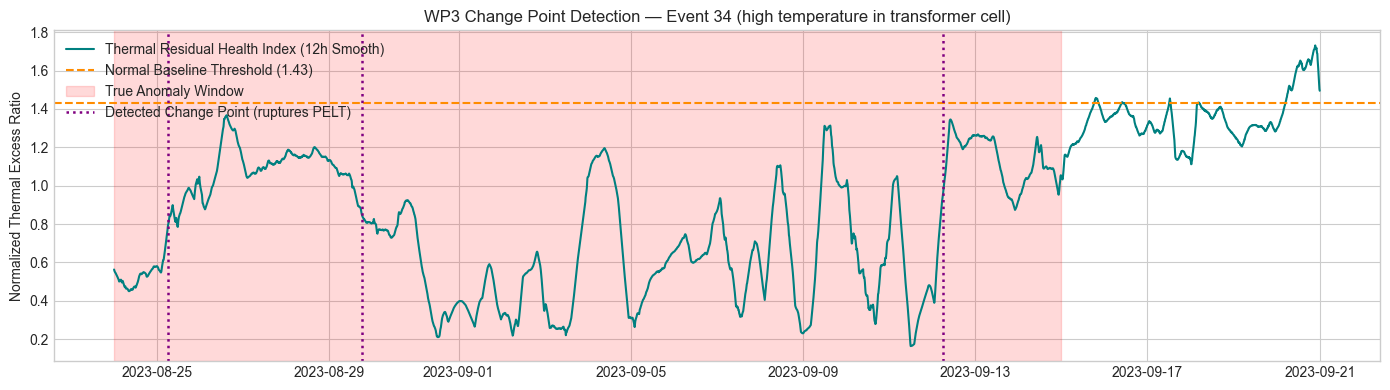

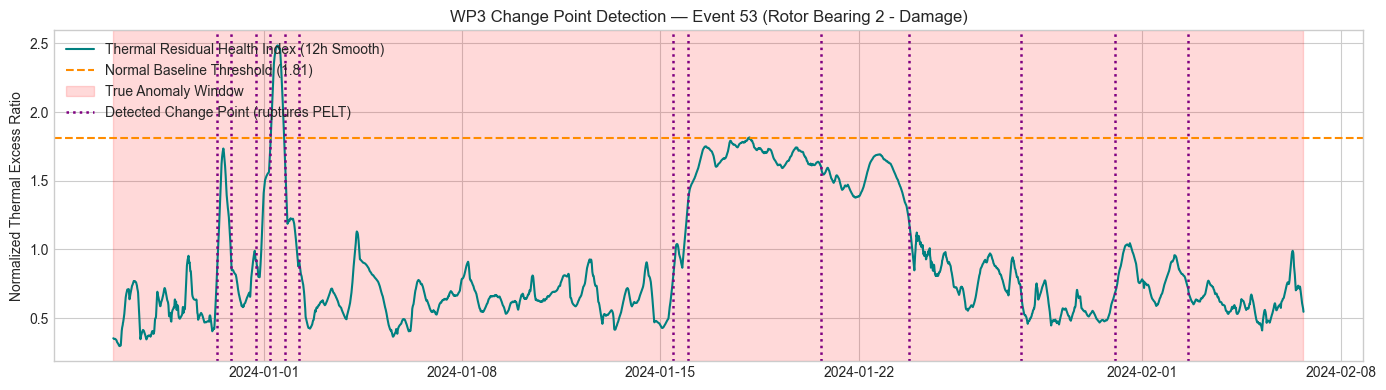

In [8]:
def detect_regime_changepoint(
    meta_df: pd.DataFrame,
    health_signal: np.ndarray,
    search_method: str = "pelt",
    penalty_scale: float = 8.0
):
    """
    Run ruptures change-point detection on the prediction period,
    comparing post-changepoint level against the normal training baseline.
    """
    train_norm = (meta_df["train_test"] == "train") & (meta_df["status_type_id"] == 0)
    train_sig = health_signal[train_norm.values]
    # Threshold calibrated at 1.05x the 99.5th percentile of normal training thermal residuals
    train_thresh = max(1.08, float(np.percentile(train_sig, 99.5)))

    pred_mask = meta_df["train_test"] == "prediction"
    pred_sig = health_signal[pred_mask.values]
    pred_status = meta_df.loc[pred_mask, "status_type_id"].values
    ts_pred = meta_df.loc[pred_mask, "time_stamp"].reset_index(drop=True)

    sig_norm = (pred_sig - np.median(train_sig)) / (np.std(train_sig) + 1e-6)
    sig_2d = sig_norm.reshape(-1, 1)

    if search_method == "pelt":
        algo = rpt.Pelt(model="l2", min_size=72, jump=6).fit(sig_2d)
        bkps = algo.predict(pen=penalty_scale * np.log(len(sig_2d)))
    else:
        algo = rpt.Binseg(model="l2", min_size=72, jump=6).fit(sig_2d)
        bkps = algo.predict(pen=penalty_scale * np.log(len(sig_2d)))

    change_points = [b for b in bkps if b < len(sig_2d)]

    # Flag segments where active-operation health index exceeds the normal threshold
    anomaly_flags = np.zeros(len(pred_sig), dtype=int)
    boundaries = [0] + change_points + [len(pred_sig)]
    for i in range(len(boundaries) - 1):
        s, e = boundaries[i], boundaries[i + 1]
        seg_active = pred_sig[s:e][pred_status[s:e] == 0]
        if len(seg_active) > 12 and np.percentile(seg_active, 90) > train_thresh:
            anomaly_flags[s:e] = 1

    return ts_pred, pred_sig, train_thresh, change_points, anomaly_flags

# Visualize WP3 Change Point Detection on Event 34 (Transformer cell) and Event 53 (Rotor Bearing 2)
for ev_id in [34, 53]:
    meta_df, X_pca, health_idx = load_and_preprocess(ev_id)
    ts_pred, pred_sig, thresh, cps, flags = detect_regime_changepoint(meta_df, health_idx, search_method="pelt")
    ev_row = event_info[event_info["event_id"] == ev_id].iloc[0]

    plt.figure(figsize=(14, 4))
    plt.plot(ts_pred, pred_sig, label="Thermal Residual Health Index (12h Smooth)", color="teal")
    plt.axhline(thresh, color="darkorange", linestyle="--", label=f"Normal Baseline Threshold ({thresh:.2f})")
    plt.axvspan(ev_row["event_start"], ev_row["event_end"], color="red", alpha=0.15, label="True Anomaly Window")
    for idx_cp, cp in enumerate(cps):
        plt.axvline(ts_pred.iloc[cp], color="purple", linestyle=":", linewidth=1.8,
                    label="Detected Change Point (ruptures PELT)" if idx_cp == 0 else None)
    plt.title(f"WP3 Change Point Detection — Event {ev_id} ({ev_row['event_description']})")
    plt.ylabel("Normalized Thermal Excess Ratio")
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

---
## Step 2: Full Benchmark Evaluation Across All 15 Datasets in Wind Farm B (WP2 vs. WP3)

Now we run both **WP2 (GMM Clustering)** and **WP3 (`ruptures` PELT Change Point Detection)** across all 15 datasets in Wind Farm B and compare:
- **True Positives (TP), False Positives (FP), False Negatives (FN), True Negatives (TN)**
- **Precision, Recall, $F_1$-Score, and $F_{0.5}$-Score (CARE Benchmark weighting)**
- **Average Early Detection Lead Time (Days before actual failure)**

In [9]:
benchmark_rows = []

for _, ev in event_info.iterrows():
    ev_id = int(ev["event_id"])
    label = ev["event_label"]
    ev_end = ev["event_end"]

    meta_df, X_pca, health_idx = load_and_preprocess(ev_id)
    train_norm = (meta_df["train_test"] == "train") & (meta_df["status_type_id"] == 0)
    pred_mask = meta_df["train_test"] == "prediction"
    ts_pred = meta_df.loc[pred_mask, "time_stamp"].reset_index(drop=True)
    pred_status = meta_df.loc[pred_mask, "status_type_id"].values

    # --- WP2: GMM Clustering on Thermal Residual PCA + Health Feature ---
    X_clust = np.column_stack([X_pca, health_idx])
    gmm = GaussianMixture(n_components=4, covariance_type="diag", reg_covar=1e-2, random_state=42)
    gmm.fit(X_clust[train_norm.values][::6])
    tr_scores = -gmm.score_samples(X_clust[train_norm.values])
    pr_scores = -gmm.score_samples(X_clust[pred_mask.values])
    gmm_thresh = np.percentile(tr_scores, 99.6)
    gmm_raw = ((pr_scores > gmm_thresh) & (pred_status == 0) & (health_idx[pred_mask.values] > 1.05)).astype(int)
    gmm_flags = (pd.Series(gmm_raw).rolling(72, min_periods=1).mean() >= 0.4).astype(int).values

    # --- WP3: ruptures PELT Change Point Detection ---
    _, _, _, cps, cpd_flags = detect_regime_changepoint(meta_df, health_idx, search_method="pelt")

    for method_name, flags in [("WP2_GMM_Clustering", gmm_flags), ("WP3_Ruptures_PELT", cpd_flags)]:
        detected = bool(np.any(flags == 1))
        lead_days = np.nan
        if detected and label == "anomaly":
            first_ts = ts_pred.iloc[int(np.argmax(flags == 1))]
            lead_days = (ev_end - first_ts).total_seconds() / (3600 * 24)

        benchmark_rows.append({
            "Method": method_name,
            "event_id": ev_id,
            "asset_id": ev["asset_id"],
            "actual_label": label,
            "detected": detected,
            "TP": int(label == "anomaly" and detected),
            "FP": int(label == "normal" and detected),
            "FN": int(label == "anomaly" and not detected),
            "TN": int(label == "normal" and not detected),
            "lead_time_days": round(lead_days, 2) if pd.notna(lead_days) else None
        })

df_bench = pd.DataFrame(benchmark_rows)
display(df_bench.pivot(index=["event_id", "asset_id", "actual_label"], columns="Method", values=["detected", "lead_time_days"]))

detected                    \
Method                         WP2_GMM_Clustering WP3_Ruptures_PELT   
event_id asset_id actual_label                                        
2        13       normal                    False             False   
7        13       anomaly                   False             False   
19       11       anomaly                   False             False   
21       0        normal                    False             False   
23       6        normal                    False             False   
27       7        anomaly                   False             False   
34       14       anomaly                   False              True   
52       14       normal                    False             False   
53       6        anomaly                   False              True   
74       11       normal                    False             False   
77       12       anomaly                   False              True   
82       5        normal                    False             False   
83       2        normal                     True              True   
86       12       normal                    False             False   
87       7        normal                    False             False   

                                   lead_time_days                    
Method                         WP2_GMM_Clustering WP3_Ruptures_PELT  
event_id asset_id actual_label                                       
2        13       normal                      NaN               NaN  
7        13       anomaly                     NaN               NaN  
19       11       anomaly                     NaN               NaN  
21       0        normal                      NaN               NaN  
23       6        normal                      NaN               NaN  
27       7        anomaly                     NaN               NaN  
34       14       anomaly                     NaN              2.75  
52       14       normal                      NaN               NaN  
53       6        anomaly                     NaN             36.45  
74       11       normal                      NaN               NaN  
77       12       anomaly                     NaN              63.0  
82       5        normal                      NaN               NaN  
83       2        normal                      NaN               NaN  
86       12       normal                      NaN               NaN  
87       7        normal                      NaN               NaN

In [10]:
# Summary Table Comparing WP2 vs WP3
summary = []
for method, grp in df_bench.groupby("Method"):
    tp, fp, fn, tn = grp["TP"].sum(), grp["FP"].sum(), grp["FN"].sum(), grp["TN"].sum()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    f05 = 1.25 * prec * rec / (0.25 * prec + rec) if (prec + rec) > 0 else 0.0
    summary.append({
        "Method": method,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1_Score": round(f1, 3),
        "F0.5_CARE_Score": round(f05, 3),
        "Avg_Lead_Time_Days": round(grp["lead_time_days"].dropna().mean(), 2)
    })

display(pd.DataFrame(summary))

,Method,TP,FP,FN,TN,Precision,Recall,F1_Score,F0.5_CARE_Score,Avg_Lead_Time_Days
0,WP2_GMM_Clustering,0,1,6,8,0.00,0.0,0.0,0.000,NaN
1,WP3_Ruptures_PELT,3,1,3,8,0.75,0.5,0.6,0.682,34.07
